# Cookie Cats A/B Test: Bootstrap

**Goal:** estimate how much the retention results would vary if the experiment were repeated,
and how confident we can be that gate_30 retains more players than gate_40.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("default")

df = pd.read_csv("../data/cookie_cats.csv")
df = df[df["sum_gamerounds"] < df["sum_gamerounds"].max()]
df.shape

(90188, 5)

In [2]:
rng = np.random.default_rng(42)
boot_rows = []

for _ in range(2000):
    sample = df.sample(frac=1, replace=True, random_state=rng)
    boot_rows.append(sample.groupby("version")[["retention_1", "retention_7"]].mean().stack())

boot = pd.DataFrame(boot_rows) * 100   # in %
boot.head()

version     gate_30                 gate_40            
        retention_1 retention_7 retention_1 retention_7
0         45.030026   19.319710   43.755487   17.921422
1         45.042925   19.025844   43.890291   18.121777
2         44.741805   19.137854   44.220995   18.127848
3         44.915728   18.991875   44.409044   18.334029
4         44.876830   19.129329   44.080049   18.086044

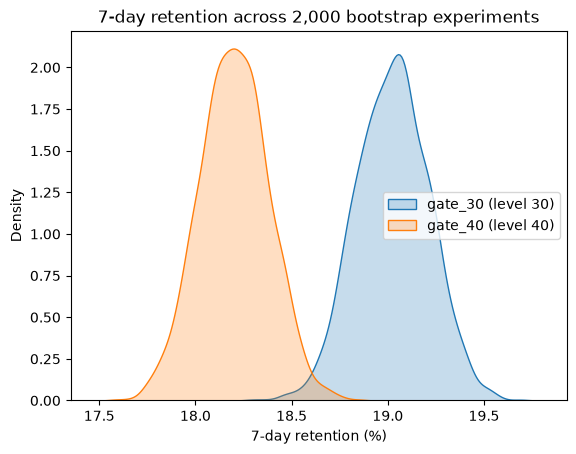

In [3]:
sns.kdeplot(boot[("gate_30", "retention_7")], fill=True, label="gate_30 (level 30)")
sns.kdeplot(boot[("gate_40", "retention_7")], fill=True, label="gate_40 (level 40)")
plt.xlabel("7-day retention (%)")
plt.title("7-day retention across 2,000 bootstrap experiments")
plt.legend()
plt.savefig("../images/bootstrap_retention7.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
summary = {}
for metric in ["retention_1", "retention_7"]:
    diff = boot[("gate_30", metric)] - boot[("gate_40", metric)]
    low, high = np.percentile(diff, [2.5, 97.5])
    summary[metric] = {
        "avg_diff_pts": round(diff.mean(), 2),
        "95%_CI": f"[{low:.2f}, {high:.2f}]",
        "P(gate_30 better)": f"{(diff > 0).mean():.1%}",
    }
pd.DataFrame(summary).T

,avg_diff_pts,95%_CI,P(gate_30 better)
retention_1,0.6,"[-0.04, 1.26]",96.2%
retention_7,0.82,"[0.32, 1.33]",100.0%


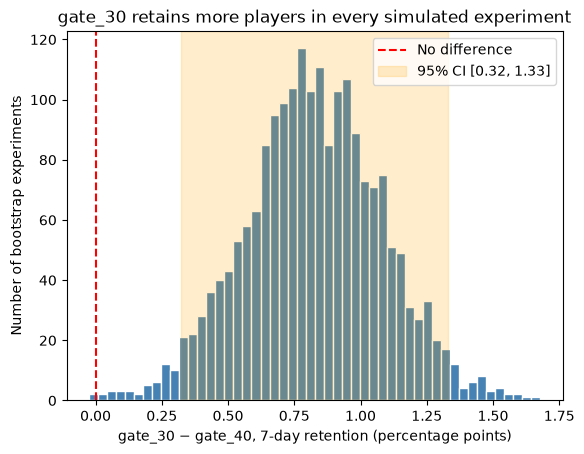

In [5]:
diff7 = boot[("gate_30", "retention_7")] - boot[("gate_40", "retention_7")]
low, high = np.percentile(diff7, [2.5, 97.5])

plt.hist(diff7, bins=50, color="steelblue", edgecolor="white")
plt.axvline(0, color="red", linestyle="--", label="No difference")
plt.axvspan(low, high, color="orange", alpha=0.2, label=f"95% CI [{low:.2f}, {high:.2f}]")
plt.xlabel("gate_30 − gate_40, 7-day retention (percentage points)")
plt.ylabel("Number of bootstrap experiments")
plt.title("gate_30 retains more players in every simulated experiment")
plt.legend()
plt.savefig("../images/bootstrap_diff_retention7.png", dpi=150, bbox_inches="tight")
plt.show()

## Bootstrap findings (2,000 resamples)

| Metric | gate_30 − gate_40 | 95% CI | gate_30 better in |
|---|---|---|---|
| 1-day retention | +0.60 pts | [−0.05, +1.26] | 96.2% of resamples |
| 7-day retention | **+0.82 pts** | **[+0.32, +1.33]** | **100% of resamples** |

- **7-day retention:** gate_30 retained more players in every one of 2,000 simulated experiments.
  The true difference is most likely between 0.3 and 1.3 percentage points. This matches the
  z-test from Step 2, so two different methods agree.
- **1-day retention:** gate_30 is ahead in 96% of resamples, but the interval includes zero,
  so it is suggestive, not conclusive (consistent with p = 0.074).
**Recommendation:** keep the first gate at **level 30**.